## 2.1 Business Understanding

The hotel management team wants to predict booking cancellations before arrival.

Early prediction enables managers to:

- Reduce revenue loss.
- Adjust overbooking strategies.
- Allocate rooms efficiently.
- Improve customer retention.

Target variable:

is_canceled

0 = Not Cancelled

1 = Cancelled

Import Libraries

In [ ]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

In [ ]:
#Load Dataset
df = pd.read_csv("hotel_bookings_cleaned 1.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,total_guests,total_nights,total_revenue,season,weekend_ratio,lead_time_category
0,1,0,2.227051,2015,5,27,1,-0.92889,-1.310240,0.247897,...,2,-2.015038,0,-0.720694,0.043967,-1.340370,-1.065314,2,-0.993748,0
1,1,0,5.923385,2015,5,27,1,-0.92889,-1.310240,0.247897,...,2,-2.015038,0,-0.720694,0.043967,-1.340370,-1.065314,2,-0.993748,0
2,1,0,-0.907814,2015,5,27,1,-0.92889,-0.786207,-1.478447,...,2,-0.530935,0,-0.720694,-1.340324,-0.949352,-0.842039,2,-0.993748,2
3,1,0,-0.851667,2015,5,27,1,-0.92889,-0.786207,-1.478447,...,2,-0.530935,0,-0.720694,-1.340324,-0.949352,-0.842039,2,-0.993748,2
4,1,0,-0.842309,2015,5,27,1,-0.92889,-0.262174,0.247897,...,2,-0.075810,0,0.540666,0.043967,-0.558334,-0.481822,2,-0.993748,2


##2.2 Data Preparation
Input Features
hotel
meal
lead_time
total_guests
reserved_room_type
market_segment
previous_cancellations

In [ ]:
y = df["is_canceled"]
X = df[[
    'hotel',
    'meal',
    'lead_time',
    'total_guests',
    'reserved_room_type',
    'market_segment',
    'previous_cancellations'
]]

Identify Categorical and Numerical Variables

In [ ]:
categorical_features = [
    'hotel',
    'meal',
    'reserved_room_type',
    'market_segment'
]
numerical_features = [
    'lead_time',
    'total_guests',
    'previous_cancellations'
]

Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

##Preprocessing Pipeline
One-Hot Encode categorical variables
Standardize numerical variables

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

##Model 1 - Logistic Regression

In [ ]:
log_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)

In [ ]:
#Evaluate Logistic Regression
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1 Score:", f1_score(y_test, y_pred_log))

Accuracy: 0.7025714046402546
Precision: 0.6829729162292673
Recall: 0.3677784058790277
F1 Score: 0.4781011169900059


In [ ]:
#Classification report
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.71      0.90      0.79     15033
           1       0.68      0.37      0.48      8845

    accuracy                           0.70     23878
   macro avg       0.70      0.63      0.64     23878
weighted avg       0.70      0.70      0.68     23878



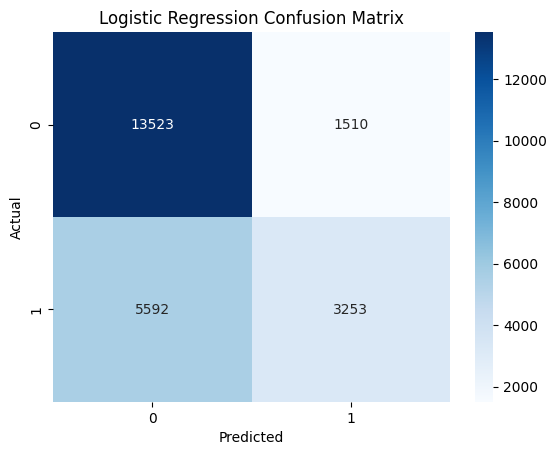

In [ ]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

#Model 2 - Decision Tree

In [ ]:
tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))

#Classification report
print(classification_report(y_test, y_pred_tree))


Accuracy: 0.7661445682217941
Precision: 0.741019955654102
Recall: 0.5667608818541549
F1 Score: 0.6422805893657911
              precision    recall  f1-score   support

           0       0.78      0.88      0.83     15033
           1       0.74      0.57      0.64      8845

    accuracy                           0.77     23878
   macro avg       0.76      0.73      0.73     23878
weighted avg       0.76      0.77      0.76     23878



##Model 3 - Random Forest

In [ ]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))

#Classification report
print(classification_report(y_test, y_pred_rf))


Accuracy: 0.7661445682217941
Precision: 0.741019955654102
Recall: 0.5667608818541549
F1 Score: 0.6422805893657911
              precision    recall  f1-score   support

           0       0.78      0.87      0.82     15033
           1       0.73      0.59      0.65      8845

    accuracy                           0.76     23878
   macro avg       0.75      0.73      0.74     23878
weighted avg       0.76      0.76      0.76     23878



In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 20, None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'max_depth': 20, 'n_estimators': 150}
Best Cross Validation Accuracy: 0.7625429051158058


In [ ]:
#Compare models
results = pd.DataFrame({
    "Model": ["Logistic Regression",
              "Decision Tree",
              "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.702571   0.682973  0.367778  0.478101
1        Decision Tree  0.766145   0.741020  0.566761  0.642281
2        Random Forest  0.764846   0.725496  0.587451  0.649216


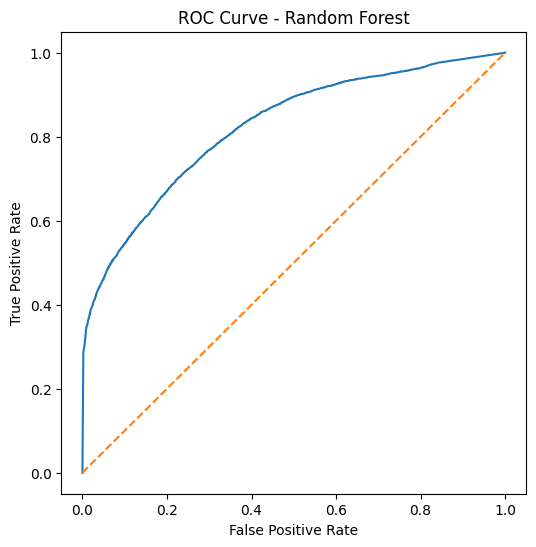

ROC-AUC = 0.8227089887831847


In [ ]:
#ROC Curve
y_prob_rf = rf_model.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")

plt.show()

print("ROC-AUC =", roc_auc_score(y_test, y_prob_rf))

In [ ]:
#Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
    'classifier__n_estimators': [100,200],
    'classifier__max_depth': [10,20,None],
    'classifier__min_samples_split': [2,5]
}

In [ ]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

In [ ]:
#Use a smaller parameter grid:
param_grid = {
    'classifier__n_estimators': [100],
    'classifier__max_depth': [10, None],
    'classifier__min_samples_split': [2]
}

In [ ]:
best_rf = grid_search.best_estimator_

y_pred_best = best_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))

best_rf_auc = roc_auc_score(
    y_test,
    best_rf.predict_proba(X_test)[:, 1]
)

print("ROC-AUC:", best_rf_auc)

Accuracy: 0.7648463020353463
Precision: 0.7254956716001117
Recall: 0.5874505370265687
F1 Score: 0.6492159680139938
ROC-AUC: 0.8227089887831847


## Business Insights

Random Forest achieved the highest prediction performance and can identify customers likely to cancel.

Hotel management can:

- Identify high risk bookings.
- Adjust overbooking policies.
- Improve revenue management.
- Offer discounts or reminders to customers likely to cancel.
- Allocate resources more efficiently.

This predictive model helps reduce financial losses caused by booking cancellations.